In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label
from scipy.stats import skew
from skimage.measure import label, regionprops
from sklearn.mixture import GaussianMixture
import pandas as pd
from skimage.feature import graycomatrix, graycoprops


In [6]:
mask_folder = "Train-Mask"
input_folder = "Train-Input"

tahlil amari: 
Mean: 2.99
Standard Deviation: 4.73
Median: 1.00
Minimum: 0
Maximum: 28
Skewness: 2.06


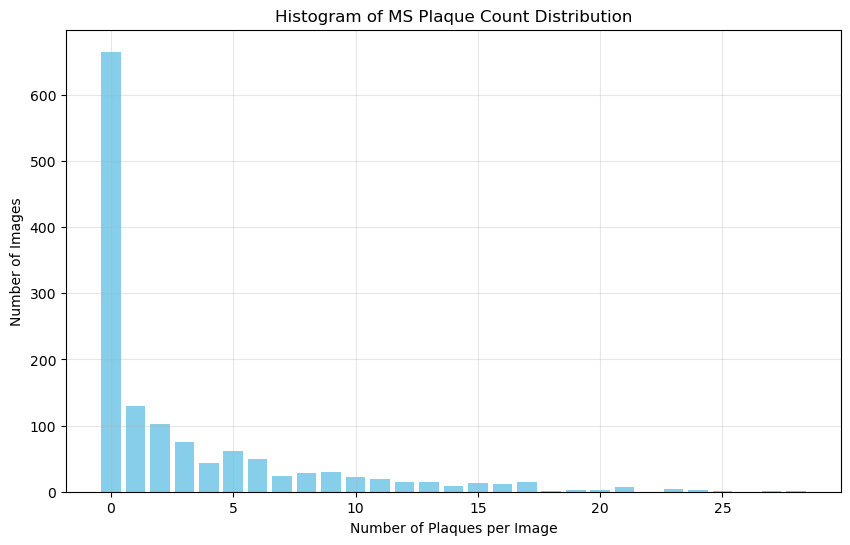

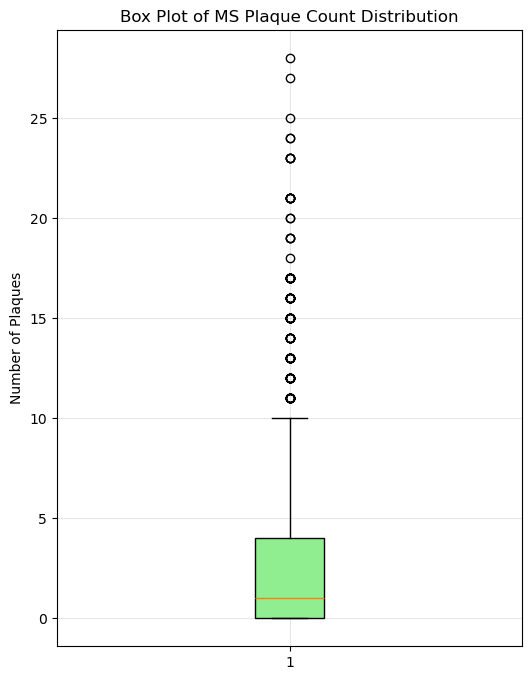

In [10]:
mask_folder = "Train-Mask"

plaque_counts = []

for mask_file in os.listdir(mask_folder):
    if mask_file.lower().endswith((".png", ".jpg", ".jpeg")):
        mask = cv2.imread(os.path.join(mask_folder, mask_file), cv2.IMREAD_GRAYSCALE)
        
        _, thresh = cv2.threshold(mask, 10, 1, cv2.THRESH_BINARY)
        
        labeled_array = label(thresh, connectivity=2)
        num_plaques = labeled_array.max()  # تعداد پلاک‌ها
        
        plaque_counts.append(num_plaques)

plaque_counts = np.array(plaque_counts)

mean_count = np.mean(plaque_counts)
std_count = np.std(plaque_counts)
median_count = np.median(plaque_counts)
min_count = np.min(plaque_counts)
max_count = np.max(plaque_counts)
skewness = skew(plaque_counts)

print("tahlil amari: ")
print(f"Mean: {mean_count:.2f}")
print(f"Standard Deviation: {std_count:.2f}")
print(f"Median: {median_count:.2f}")
print(f"Minimum: {min_count}")
print(f"Maximum: {max_count}")
print(f"Skewness: {skewness:.2f}")

# histogram
plt.figure(figsize=(10, 6))
plt.hist(plaque_counts, bins=range(min_count, max_count + 2), align='left', rwidth=0.8, color='skyblue')
plt.xlabel("Number of Plaques per Image")
plt.ylabel("Number of Images")
plt.title("Histogram of MS Plaque Count Distribution")
plt.grid(True, alpha=0.3)
plt.show()

# Boxplot
plt.figure(figsize=(6, 8))
plt.boxplot(plaque_counts, vert=True, patch_artist=True, boxprops=dict(facecolor='lightgreen'))
plt.ylabel("Number of Plaques")
plt.title("Box Plot of MS Plaque Count Distribution")
plt.grid(True, alpha=0.3)
plt.show()


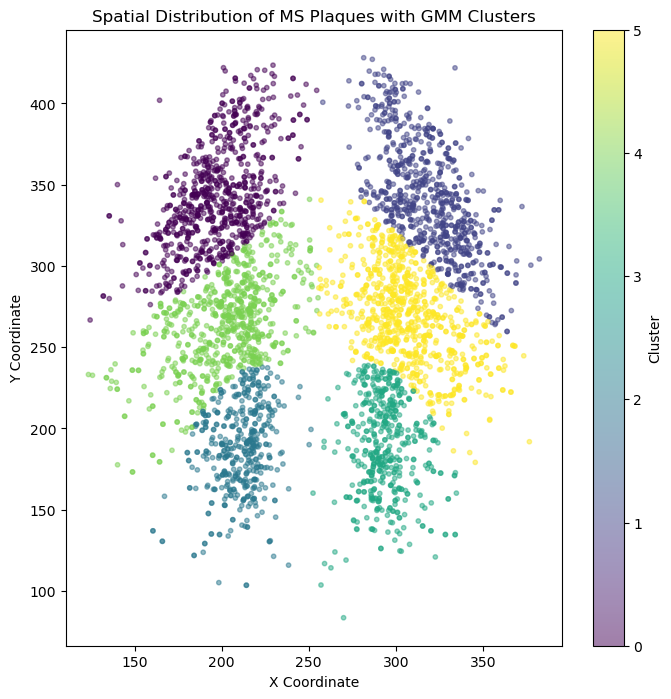

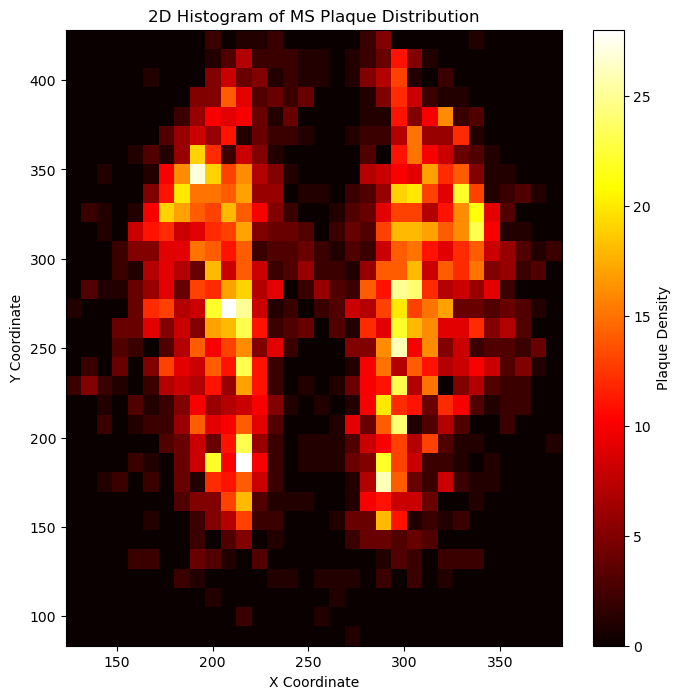

Mean X: 256.67337955498886
Mean Y: 276.7646922349131
Std X: 57.22323924455439
Std Y: 66.28278220543395
Average number of plaques per image: 2.988888888888889


In [11]:
centroids = []
plaque_counts = []

for mask_file in os.listdir(mask_folder):
    if mask_file.lower().endswith(".png"):
        mask = cv2.imread(os.path.join(mask_folder, mask_file), cv2.IMREAD_GRAYSCALE)
        
        thresh = cv2.threshold(mask, 10, 1, cv2.THRESH_BINARY)[1]
        
        labels = label(thresh)
        regions = regionprops(labels, intensity_image=mask)
        
        plaque_counts.append(len(regions)) 
        
        for region in regions:
            cy, cx = region.weighted_centroid 
            centroids.append([cx, cy])

centroids = np.array(centroids)

gmm = GaussianMixture(n_components=6, random_state=42)
gmm.fit(centroids)
cluster_labels = gmm.predict(centroids)

plt.figure(figsize=(8, 8))
plt.scatter(centroids[:, 0], centroids[:, 1], c=cluster_labels, cmap='viridis', s=10, alpha=0.5)
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("Spatial Distribution of MS Plaques with GMM Clusters")
plt.colorbar(label="Cluster")
plt.show()

plt.figure(figsize=(8, 8))
plt.hist2d(centroids[:, 0], centroids[:, 1], bins=32, cmap='hot')
plt.colorbar(label="Plaque Density")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("2D Histogram of MS Plaque Distribution")
plt.show()

print("Mean X:", np.mean(centroids[:, 0]))
print("Mean Y:", np.mean(centroids[:, 1]))
print("Std X:", np.std(centroids[:, 0]))
print("Std Y:", np.std(centroids[:, 1]))
print("Average number of plaques per image:", np.mean(plaque_counts))


          file  plaque_id   area  mean_intensity  std_intensity  skewness  \
0  A (448).png          1   85.0      194.541176      12.440496 -0.178332   
1  A (448).png          2  156.0      209.442308      10.091403  0.212500   
2  A (448).png          3  659.0      190.330804      23.029370 -0.409869   
3  A (448).png          5   69.0      207.826087      28.824786 -0.477324   
4  A (448).png          7   53.0      209.283019      16.564770 -1.214824   

      contrast  homogeneity    energy  correlation  
0  6194.283333     0.317011  0.234447     0.622405  
1  8441.675926     0.321966  0.202569     0.538151  
2  1731.717647     0.800265  0.776215     0.852086  
3  5661.342857     0.512566  0.473588     0.744839  
4  4918.571429     0.356045  0.295151     0.757129  


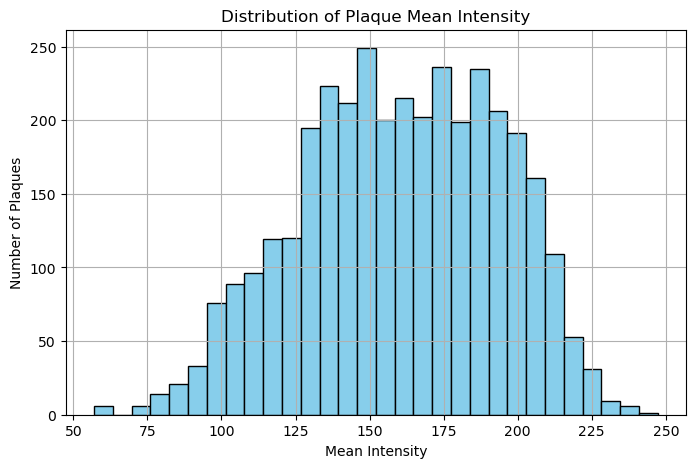

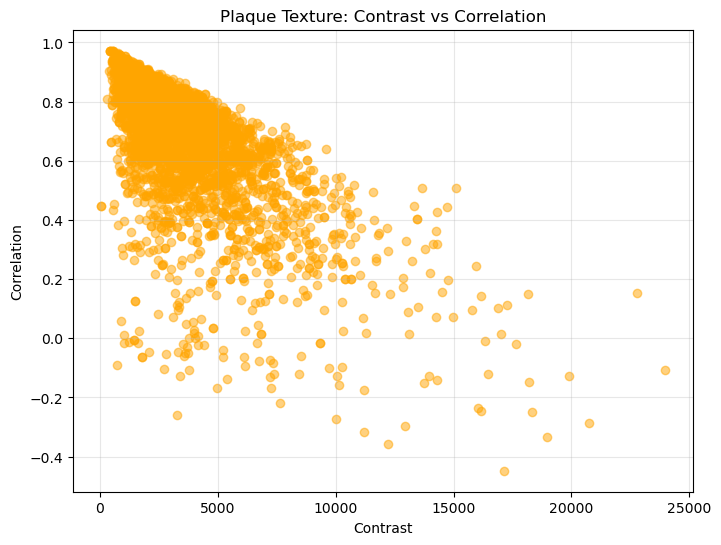

In [13]:

texture_features = []

valid_exts = [".png", ".jpg", ".jpeg", ".tif"]
mask_files = [f for f in os.listdir(mask_folder) 
              if any(f.lower().endswith(ext) for ext in valid_exts)]

for mask_file in mask_files:
    mask_path = os.path.join(mask_folder, mask_file)
    input_path = os.path.join(input_folder, mask_file)

    if not os.path.exists(input_path):
        input_file_try = mask_file.replace(".png", ".jpg")
        input_path = os.path.join(input_folder, input_file_try)
        if not os.path.exists(input_path):
            print(f"[هشدار]: ورودی پیدا نشد برای {mask_file}")
            continue

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    input_img = cv2.imread(input_path, cv2.IMREAD_GRAYSCALE)

    # اگر یکی از تصاویر بارگذاری نشد
    if mask is None or input_img is None:
        print(f"[خطا]: تصویر ماسک یا ورودی نامعتبر برای {mask_file}")
        continue

    binary = (mask > 10).astype(np.uint8)

    labeled_array = label(binary, connectivity=2)
    regions = regionprops(labeled_array)

    for region in regions:
        if region.area < 10:
            continue

        plaque_mask = (labeled_array == region.label).astype(np.uint8)
        plaque_pixels = input_img[plaque_mask == 1]

        mean_intensity = np.mean(plaque_pixels)
        std_intensity = np.std(plaque_pixels)
        skewness = ((np.mean((plaque_pixels - mean_intensity) ** 3))
                    / (std_intensity ** 3 + 1e-6))

        plaque_region = input_img * plaque_mask
        region_box = region.bbox
        minr, minc, maxr, maxc = region_box

        crop = plaque_region[minr:maxr, minc:maxc]
        try:
            # تعداد پیکسل‌های غیرصفر باید کافی باشد
            if np.count_nonzero(crop) < 10:
                raise ValueError("پلاک خیلی کوچک است برای GLCM.")

            # نرمال‌سازی به levels درست (0 تا 255)
            glcm = graycomatrix(crop, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
            contrast = graycoprops(glcm, 'contrast')[0, 0]
            homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
            energy = graycoprops(glcm, 'energy')[0, 0]
            correlation = graycoprops(glcm, 'correlation')[0, 0]
        except Exception as e:
            print(f"[GLCM]: پلاک {mask_file}-{region.label} قابل محاسبه نیست: {e}")
            contrast = homogeneity = energy = correlation = np.nan

        texture_features.append({
            "file": mask_file,
            "plaque_id": region.label,
            "area": region.area,
            "mean_intensity": mean_intensity,
            "std_intensity": std_intensity,
            "skewness": skewness,
            "contrast": contrast,
            "homogeneity": homogeneity,
            "energy": energy,
            "correlation": correlation
        })

df = pd.DataFrame(texture_features)
print(df.head())
df.to_csv("plaque_texture_features.csv", index=False) 

plt.figure(figsize=(8,5))
df["mean_intensity"].hist(bins=30, color="skyblue", edgecolor="black")
plt.xlabel("Mean Intensity")
plt.ylabel("Number of Plaques")
plt.title("Distribution of Plaque Mean Intensity")
plt.show()

# scatter plot: Contrast vs Correlation
plt.figure(figsize=(8,6))
plt.scatter(df["contrast"], df["correlation"], alpha=0.5, c="orange")
plt.xlabel("Contrast")
plt.ylabel("Correlation")
plt.title("Plaque Texture: Contrast vs Correlation")
plt.grid(True, alpha=0.3)
plt.show()
